# OP-FL v2 — 03. Niveau 2 (observation centrée par site) et test de stress

**Point de départ (notebook 02).** H1 = PARTIEL : le canal d'observation améliore la discrimination (+0,004 AUROC) et ce gain se transporte sans perte.
Mais l'analyse exploratoire par hôpital (étape 12) montre que le masque **décale la calibration d'un hôpital à l'autre** :
|CITL| par hôpital tenu à l'écart plus grand pour `x_obs` que pour `x_only` (médiane +0,039, Wilcoxon p = 0,019 ; GRU-D +0,051, p = 0,003).
Interprétation : le niveau de risque prédit dépend des habitudes de mesure de l'hôpital.

**Ce notebook teste deux choses :**
1. **Niveau 2** (`x_obs_site`) : M, Δ et C sont remplacés par leur **écart à la moyenne de l'hôpital** (par heure et par variable), calculée sur le split `train` de l'hôpital **sans label**. Pour un hôpital nouveau, ses données non labellisées suffisent. Le modèle ne voit plus « combien cet hôpital mesure », seulement « ce patient est-il plus ou moins mesuré que d'habitude ici ».
2. **Test de stress** : les 60 hôpitaux de développement sont classés par couverture en gaz du sang et lactate (sans label). On entraîne sur une moitié et on évalue sur l'autre, dans les deux sens. C'est le cas où l'hypothèse prédit l'échec du masque brut.

| Modèle | Entrée | Plis LOHO | Test de stress |
|---|---|---|---|
| `x_only`, `obs_only`, `x_obs`, `grud` | brute | repris du notebook 02 | entraînés ici |
| `x_obs_site` | [X, M̃, Δ̃, C̃] centrés par site (niveau 2) | entraîné ici | entraîné ici |
| `obs_site_only` | [M̃, Δ̃, C̃] seuls | entraîné ici | entraîné ici |

Mêmes hyperparamètres, mêmes seeds et même sélection du meilleur round (val des hôpitaux d'entraînement) que le notebook 02.

**Pré-enregistrement pour la fin du projet** : l'évaluation unique du test verrouillé (96 hôpitaux) comparera aussi le |CITL| par hôpital de `x_only`, `x_obs` et du meilleur modèle relatif au site. Ce sera la confirmation indépendante du résultat exploratoire de l'étape 12.

## Étape 0 — Configuration

Les hyperparamètres sont **relus** dans `results/02_baselines/config.json` pour être identiques au notebook 02.

In [1]:
# ============================================================
# ÉTAPE 0 — CONFIGURATION
# ============================================================
import sys, os, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
SRC_DIR = PROJECT_DIR / "src"
RES02 = PROJECT_DIR / "results" / "02_baselines"
RES_DIR = PROJECT_DIR / "results" / "03_niveau2_stress"
PRED_DIR, HIST_DIR, FIG_DIR = RES_DIR / "preds", RES_DIR / "history", RES_DIR / "figures"
for d in [PRED_DIR, HIST_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((DATA_DIR / "splits" / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, f"Protocole inattendu ({protocol['hash']})."

cfg02 = json.loads((RES02 / "config.json").read_text(encoding="utf-8"))
assert cfg02["protocol_hash"] == protocol["hash"]
CFG = cfg02["cfg"]                       # mêmes hyperparamètres que le notebook 02
TASK = cfg02["task"]
SEEDS = [11, 22, 33]                     # seeds déjà calculées dans le notebook 02
FOLDS = list(range(protocol["n_folds"]))
RAW_MODELS = ["x_only", "obs_only", "x_obs", "grud"]
SITE_MODELS = {"x_obs_site": "x_obs", "obs_site_only": "obs_only"}   # nom -> architecture, sur données centrées
ALL_MODELS = RAW_MODELS + list(SITE_MODELS)
ALPHA = 50.0                 # rétrécissement de la moyenne de l'hôpital vers celle des hôpitaux d'entraînement (pseudo-séjours)
BLOODGAS = ["lactate", "pH", "paO2", "paCO2", "FiO2"]
MIN_EVENTS_HOSP = cfg02["min_events_hosp"]
N_BOOT = 200

missing02 = [(m, f, s) for m in RAW_MODELS for f in FOLDS for s in SEEDS
             if not (RES02 / "preds" / f"{m}__fold{f}__seed{s}.parquet").exists()]
assert not missing02, f"Prédictions du notebook 02 manquantes : {missing02[:5]} ..."

N_THREADS = max(1, (os.cpu_count() or 2) - 1)
torch.set_num_threads(N_THREADS)
(RES_DIR / "config.json").write_text(json.dumps(
    {"task": TASK, "seeds": SEEDS, "cfg": CFG, "alpha": ALPHA, "site_models": SITE_MODELS,
     "protocol_hash": protocol["hash"], "min_events_hosp": MIN_EVENTS_HOSP}, indent=2), encoding="utf-8")
print(f"PyTorch {torch.__version__} | {N_THREADS} threads | protocole {protocol['hash']} | CFG = {CFG}")

PyTorch 2.9.1+cpu | 3 threads | protocole d92099ea7c11d517 | CFG = {'rounds': 30, 'client_frac': 0.5, 'local_epochs': 1, 'lr': 0.001, 'batch_size': 64, 'hidden': 64, 'head': 32, 'dropout': 0.1, 'grad_clip': 1.0}


## Étape 1 — Module `src/opfl_site.py`

* `make_normalizer` : statistiques de normalisation sur le split `train` d'une liste quelconque d'hôpitaux (même calcul que le notebook 01, étape 10). Nécessaire pour le test de stress, dont les groupes ne sont pas des plis.
* `load_split` : charge une séparation entraînement / écart ; pour les hôpitaux tenus à l'écart, charge aussi leur split `train` **sans label** (M, Δ, C seulement).
* `center_obs_` : le niveau 2. Moyenne de l'hôpital par heure et par variable, rétrécie vers la moyenne des hôpitaux d'entraînement avec `ALPHA` pseudo-séjours (utile pour les petits hôpitaux).
* Fonctions d'analyse : métriques par exécution et par hôpital, comparaison des |CITL| par hôpital (Wilcoxon apparié), méta-analyse des gains d'AUROC par hôpital.

## Étape 2 — Tests unitaires

1. `make_normalizer` sur les hôpitaux d'entraînement du pli 0 doit redonner exactement `normalizers/fold_0.json`.
2. Après centrage, la moyenne de M̃ sur le split train d'un hôpital doit être faible (elle n'est pas exactement nulle à cause du rétrécissement).
3. Les données non labellisées d'un hôpital tenu à l'écart ne contiennent aucun label.

In [2]:
# ============================================================
# ÉTAPE 2 — IMPORT ET TESTS UNITAIRES
# ============================================================
import opfl_data, opfl_metrics, opfl_models, opfl_fed, opfl_site
for m in (opfl_data, opfl_metrics, opfl_models, opfl_fed, opfl_site):
    importlib.reload(m)
import opfl_data as od
from opfl_fed import run_federated
from opfl_metrics import mean_ci_t
from opfl_site import (make_normalizer, load_split, center_obs_, metrics_from_preds,
                       hospital_means, compare_abs_citl, meta_auroc_gain)

# 1) normaliseur identique au notebook 01
tr0, ho0 = od.fold_hospitals(DATA_DIR, 0)
ref, new = od.load_normalizer(DATA_DIR, 0), make_normalizer(DATA_DIR, tr0, ho0)
for k in ["x_mean", "x_std", "s_mean", "s_std"]:
    assert np.allclose(ref[k], new[k], rtol=1e-6, atol=1e-8), k
assert ref["x_count"] == new["x_count"] and ref["dx_top_codes"] == new["dx_top_codes"]

# 2) et 3) centrage sur un petit sous-ensemble du pli 0
fd_small = load_split(DATA_DIR, tr0[:3], ho0[:2], ref, task=TASK)
h_held = fd_small["held_h"][0]
assert set(fd_small["clients"][h_held]["unlabeled"]) == {"M", "D", "C"}, "des labels dans les données non labellisées"
m_before = float(fd_small["clients"][tr0[0]]["train"]["M"].mean())
center_obs_(fd_small, ALPHA)
m_after = float(fd_small["clients"][tr0[0]]["train"]["M"].mean())
assert abs(m_after) < 0.05 and "unlabeled" not in fd_small["clients"][h_held]
try:
    center_obs_(fd_small, ALPHA); raise AssertionError("double centrage accepté")
except RuntimeError:
    pass
del fd_small
print(f"Normaliseur identique au pli 0 : OK | moyenne de M avant {m_before:.3f}, après centrage {m_after:+.4f}")
print("Tests unitaires : OK")

Normaliseur identique au pli 0 : OK | moyenne de M avant 0.191, après centrage +0.0001
Tests unitaires : OK


## Étape 3 — Groupes du test de stress (définis sans label)

Score de chaque hôpital de développement : couverture moyenne de lactate, pH, paO2, paCO2 et FiO2 sur son split `train` (fichier `local_stats.json`, notebook 01).
Les 30 hôpitaux au score le plus bas forment le groupe « bas », les 30 autres le groupe « haut ».

* `haut_vers_bas` : entraînement sur les hôpitaux qui mesurent beaucoup les gaz du sang, évaluation sur ceux qui en mesurent peu ;
* `bas_vers_haut` : l'inverse.

La mortalité par groupe est affichée à titre **descriptif** ; elle n'intervient pas dans la définition des groupes.

In [3]:
# ============================================================
# ÉTAPE 3 — GROUPES DU TEST DE STRESS (SANS LABEL)
# ============================================================
feats = od.load_features(str(DATA_DIR))
local = json.loads((DATA_DIR / "normalizers" / "local_stats.json").read_text(encoding="utf-8"))
manifest = pd.read_csv(DATA_DIR / "clients" / "manifest.csv").set_index("hospitalid")
dev = sorted(int(h) for k in protocol["folds"] for h in protocol["folds"][k])
bg_idx = [feats["features"].index(v) for v in BLOODGAS]
score = pd.Series({h: float(np.mean([local[str(h)]["coverage"][i] for i in bg_idx])) for h in dev},
                  name="couverture_gaz_du_sang").sort_values(kind="stable")
half = len(score) // 2
low, high = sorted(score.index[:half].tolist()), sorted(score.index[half:].tolist())
STRESS = {"haut_vers_bas": (high, low), "bas_vers_haut": (low, high)}
(RES_DIR / "stress_groups.json").write_text(json.dumps(
    {"score": "couverture moyenne (split train) de " + ", ".join(BLOODGAS),
     "bas": low, "haut": high, "seuil": float((score.iloc[half - 1] + score.iloc[half]) / 2)}, indent=2), encoding="utf-8")

desc = pd.DataFrame({
    g: {"hôpitaux": len(hs), "séjours": int(manifest.loc[hs, "n_stays"].sum()),
        "séjours train": int(manifest.loc[hs, "n_train"].sum()),
        "couverture gaz du sang (moy.)": float(score.loc[hs].mean()),
        "couverture min": float(score.loc[hs].min()), "couverture max": float(score.loc[hs].max()),
        "mortalité (descriptif)": float(np.average(manifest.loc[hs, "mortality"], weights=manifest.loc[hs, "n_stays"]))}
    for g, hs in [("bas", low), ("haut", high)]}).T
display(desc.round(3))

,hôpitaux,séjours,séjours train,couverture gaz du sang (moy.),couverture min,couverture max,mortalité (descriptif)
bas,30.0,32841.0,22989.0,0.265,0.072,0.382,0.080
haut,30.0,33253.0,23279.0,0.498,0.388,0.669,0.107


## Étape 4 — Exécutions à faire et estimation du temps

Durées tirées du notebook 02 (`runs.csv`), corrigées par la taille du split `train` des hôpitaux d'entraînement.

In [4]:
# ============================================================
# ÉTAPE 4 — EXÉCUTIONS À FAIRE ET ESTIMATION DU TEMPS
# ============================================================
def pred_path(protocol_name, split_name, model, seed):
    return PRED_DIR / f"{protocol_name}__{split_name}__{model}__seed{seed}.parquet"

PLANS = []   # (protocole, séparation, hôpitaux d'entraînement, hôpitaux tenus à l'écart, modèles)
for f in FOLDS:
    tr, ho = od.fold_hospitals(DATA_DIR, f)
    PLANS.append(("loho", f"fold{f}", tr, ho, list(SITE_MODELS)))
for name, (tr, ho) in STRESS.items():
    PLANS.append(("stress", name, tr, ho, ALL_MODELS))

runs02 = pd.read_csv(RES02 / "runs.csv").drop_duplicates(["model", "fold", "seed"], keep="last")
sec = runs02.groupby("model")["seconds"].mean().to_dict()
sec.update({k: sec[v] for k, v in SITE_MODELS.items()})
n_train_loho = np.mean([manifest.loc[od.fold_hospitals(DATA_DIR, f)[0], "n_train"].sum() for f in FOLDS])

todo, est = [], 0.0
for proto, split, tr, ho, models in PLANS:
    scale = manifest.loc[tr, "n_train"].sum() / n_train_loho
    for m in models:
        for s in SEEDS:
            if not pred_path(proto, split, m, s).exists():
                todo.append((proto, split, m, s))
                est += sec[m] * scale
print(f"Exécutions prévues : {sum(len(p[4]) for p in PLANS) * len(SEEDS)} | restant à faire : {len(todo)}")
print(f"Durée estimée : {est / 3600:.1f} h")
display(pd.DataFrame(todo, columns=["protocole", "séparation", "modèle", "seed"]).groupby(["protocole", "modèle"]).size().rename("à faire"))

Exécutions prévues : 66 | restant à faire : 66
Durée estimée : 3.7 h


protocole  modèle       
loho       obs_site_only    15
           x_obs_site       15
stress     grud              6
           obs_only          6
           obs_site_only     6
           x_obs             6
           x_obs_site        6
           x_only            6
Name: à faire, dtype: int64

## Étape 5 — Boucle d'entraînement (reprise automatique)

Pour chaque séparation : les modèles bruts d'abord, puis centrage par site **en place** et modèles relatifs au site.
Plis LOHO : seuls `x_obs_site` et `obs_site_only` sont entraînés (les modèles bruts viennent du notebook 02).
Une exécution terminée n'est jamais refaite : relancez la cellule après une interruption.

In [5]:
# ============================================================
# ÉTAPE 5 — BOUCLE D'ENTRAÎNEMENT : PLIS LOHO (NIVEAU 2) PUIS TEST DE STRESS
# ============================================================
runs_csv = RES_DIR / "runs.csv"
t_start, n_done_now = time.time(), 0

def save_run(proto, split, model, seed, preds, hist, info):
    hist.assign(protocol=proto, split=split, model=model, seed=seed).to_csv(
        HIST_DIR / f"{proto}__{split}__{model}__seed{seed}.csv", index=False)
    pd.DataFrame([{"protocol": proto, "split": split, "model": model, "seed": seed, **info,
                   "finished_at": pd.Timestamp.now().isoformat(timespec="seconds")}]).to_csv(
        runs_csv, mode="a", header=not runs_csv.exists(), index=False)
    preds.assign(protocol=proto, split=split, model=model, seed=seed).to_parquet(
        pred_path(proto, split, model, seed), index=False)                      # en dernier

for proto, split, tr, ho, models in PLANS:
    raw = [(m, s) for m in models if m in RAW_MODELS for s in SEEDS if not pred_path(proto, split, m, s).exists()]
    site = [(m, s) for m in models if m in SITE_MODELS for s in SEEDS if not pred_path(proto, split, m, s).exists()]
    if not raw and not site:
        print(f"{proto} | {split} : déjà complet.")
        continue
    norm = od.load_normalizer(DATA_DIR, int(split[4:])) if proto == "loho" else make_normalizer(DATA_DIR, tr, ho)
    if proto == "stress":
        (RES_DIR / f"normalizer_{split}.json").write_text(json.dumps(norm), encoding="utf-8")
    fd = load_split(DATA_DIR, tr, ho, norm, task=TASK)
    for phase, items in (("brut", raw), ("site", site)):
        if phase == "site" and items:
            center_obs_(fd, ALPHA)
        for m, s in items:
            arch = SITE_MODELS.get(m, m)
            print(f"[{len(todo) - len([1 for t in todo if not pred_path(*t).exists()]) + 1}/{len(todo)}] "
                  f"{proto} | {split} | {m} | seed {s}")
            preds, hist, info = run_federated(fd, arch, s, CFG)
            save_run(proto, split, m, s, preds, hist, info)
            n_done_now += 1
            left = sum(not pred_path(*t).exists() for t in todo)
            print(f"    meilleur round {info['best_round']} | AUROC val {info['best_val_auroc']:.4f} | "
                  f"{info['seconds'] / 60:.1f} min | reste ≈ {(time.time() - t_start) / n_done_now * left / 3600:.1f} h")
    del fd

left = sum(not pred_path(*t).exists() for t in todo)
print(f"\nTerminé. Exécutions restantes : {left}")

[1/66] loho | fold0 | x_obs_site | seed 11
    round 30/30 | perte 0.2215 | AUROC val 0.8503 | 9.1 s    
    meilleur round 29 | AUROC val 0.8506 | 6.2 min | reste ≈ 7.0 h
[2/66] loho | fold0 | x_obs_site | seed 22
    round 30/30 | perte 0.2213 | AUROC val 0.8484 | 19.6 s   
    meilleur round 25 | AUROC val 0.8495 | 6.8 min | reste ≈ 7.1 h
[3/66] loho | fold0 | x_obs_site | seed 33
    round 30/30 | perte 0.2298 | AUROC val 0.8503 | 10.4 s   
    meilleur round 30 | AUROC val 0.8503 | 5.8 min | reste ≈ 6.7 h
[4/66] loho | fold0 | obs_site_only | seed 11
    round 30/30 | perte 0.2615 | AUROC val 0.7775 | 8.2 s    
    meilleur round 29 | AUROC val 0.7807 | 4.3 min | reste ≈ 4.5 h
[12/66] loho | fold1 | obs_site_only | seed 33
    round 30/30 | perte 0.2732 | AUROC val 0.7790 | 10.0 s   
    meilleur round 30 | AUROC val 0.7790 | 4.6 min | reste ≈ 4.4 h
[13/66] loho | fold2 | x_obs_site | seed 11
    round 30/30 | perte 0.2278 | AUROC val 0.8484 | 7.8 s    
    meilleur round 30 | AUR

## Étape 6 — Métriques par exécution et par hôpital

Rassemble les prédictions du notebook 02 (plis LOHO, modèles bruts, seeds 11/22/33) et celles de ce notebook, puis calcule les métriques poolées et par hôpital (≥ 5 décès et ≥ 5 survivants).

In [6]:
# ============================================================
# ÉTAPE 6 — MÉTRIQUES PAR EXÉCUTION ET PAR HÔPITAL
# ============================================================
p02 = []
for m in RAW_MODELS:
    for f in FOLDS:
        for s in SEEDS:
            d = pd.read_parquet(RES02 / "preds" / f"{m}__fold{f}__seed{s}.parquet")
            p02.append(d.drop(columns="fold").assign(protocol="loho", split=f"fold{f}"))
preds = pd.concat(p02 + [pd.read_parquet(p) for p in sorted(PRED_DIR.glob("*.parquet"))], ignore_index=True)
preds = preds[preds["role"].isin(["intra", "transfer"])]
print(f"{preds.groupby(['protocol', 'split', 'model', 'seed']).ngroups} exécutions, {len(preds)} prédictions")

runs_m, hosp_m = metrics_from_preds(preds, ["protocol", "split", "model", "seed"], MIN_EVENTS_HOSP)
runs_m.to_csv(RES_DIR / "metrics_runs.csv", index=False)
hosp_m.to_csv(RES_DIR / "metrics_hospital.csv", index=False)
display(runs_m.groupby(["protocol", "role", "model"]).size().unstack("model"))

126 exécutions, 1903356 prédictions


model              grud  obs_only  obs_site_only  x_obs  x_obs_site  x_only
protocol role                                                              
loho     intra       15        15             15     15          15      15
         transfer    15        15             15     15          15      15
stress   intra        6         6              6      6           6       6
         transfer     6         6              6      6           6       6

## Étape 7 — Résultats sur les plis LOHO : le niveau 2

* Tableau : AUROC poolée, macro-AUROC (intra-hôpital), CITL.
* Différences appariées par pli (moyenne des seeds, IC 95 % de Student sur les 5 plis).
* Par hôpital tenu à l'écart (60 hôpitaux) : |CITL| (Wilcoxon apparié) et méta-analyse des différences d'AUROC.

In [7]:
# ============================================================
# ÉTAPE 7 — RÉSULTATS LOHO : NIVEAU 2
# ============================================================
L = runs_m[runs_m["protocol"] == "loho"]
KEYM = ["auroc", "macro_auroc", "auprc", "brier", "cal_citl", "cal_slope"]
agg = L.groupby(["role", "model"])[KEYM].agg(["mean", "std"])
tab_loho = pd.DataFrame({k: agg[(k, "mean")].map("{:.4f}".format) + " ± " + agg[(k, "std")].map("{:.4f}".format) for k in KEYM})
tab_loho = tab_loho.reindex(pd.MultiIndex.from_product([["intra", "transfer"], ALL_MODELS]))
tab_loho.to_csv(RES_DIR / "loho_summary.csv")
display(tab_loho)

def paired_by_split(R, a, b, metric, role):
    w = R[R["role"] == role].pivot_table(index=["split", "seed"], columns="model", values=metric)
    return (w[b] - w[a]).groupby("split").mean().to_numpy()

rows = []
for a, b in [("x_obs", "x_obs_site"), ("x_only", "x_obs_site"), ("obs_only", "obs_site_only")]:
    for metric in ["auroc", "macro_auroc", "brier"]:
        for role in ["intra", "transfer"]:
            d = paired_by_split(L, a, b, metric, role)
            m_, lo, hi = mean_ci_t(d)
            rows.append({"comparaison": f"{b} - {a}", "métrique": metric, "rôle": role, "diff": m_,
                         "ic_bas": lo, "ic_haut": hi, "plis > 0": f"{int((d > 0).sum())}/{len(d)}"})
diff_loho = pd.DataFrame(rows)
diff_loho.to_csv(RES_DIR / "loho_paired_differences.csv", index=False)
display(diff_loho.round(4))

w_loho = hospital_means(hosp_m[hosp_m["protocol"] == "loho"], "transfer", "cal_citl")
citl_loho = pd.DataFrame([compare_abs_citl(w_loho, a, b) for a, b in
                          [("x_only", "x_obs"), ("x_only", "grud"), ("x_obs", "x_obs_site"),
                           ("x_only", "x_obs_site"), ("obs_only", "obs_site_only")]])
citl_loho.to_csv(RES_DIR / "loho_citl_par_hopital.csv", index=False)
print("|CITL| par hôpital tenu à l'écart (moyenne des seeds) :")
display(citl_loho.round(4))

tr_loho = preds[(preds["protocol"] == "loho") & (preds["role"] == "transfer")]
meta_loho = pd.DataFrame([meta_auroc_gain(tr_loho, a, b, MIN_EVENTS_HOSP, N_BOOT) for a, b in
                          [("x_only", "x_obs"), ("x_obs", "x_obs_site"), ("x_only", "x_obs_site")]])
meta_loho.to_csv(RES_DIR / "loho_meta_auroc.csv", index=False)
print("Méta-analyse des différences d'AUROC par hôpital (transfert) :")
display(meta_loho.round(4))

auroc      macro_auroc            auprc            brier         cal_citl        cal_slope
intra    x_only         0.8510 ± 0.0020  0.8454 ± 0.0031  0.4519 ± 0.0052  0.0664 ± 0.0007  0.0767 ± 0.0973  0.9680 ± 0.0371
         obs_only       0.7704 ± 0.0046  0.7742 ± 0.0053  0.2994 ± 0.0082  0.0757 ± 0.0009  0.0698 ± 0.0946  1.0071 ± 0.0211
         x_obs          0.8553 ± 0.0017  0.8539 ± 0.0023  0.4566 ± 0.0058  0.0661 ± 0.0008  0.1244 ± 0.1235  0.9694 ± 0.0256
         grud           0.8523 ± 0.0022  0.8504 ± 0.0022  0.4539 ± 0.0058  0.0664 ± 0.0007  0.1068 ± 0.1215  0.9536 ± 0.0343
         x_obs_site     0.8553 ± 0.0019  0.8521 ± 0.0030  0.4581 ± 0.0052  0.0658 ± 0.0008  0.0941 ± 0.0962  0.9577 ± 0.0303
         obs_site_only  0.7785 ± 0.0031  0.7784 ± 0.0047  0.3087 ± 0.0061  0.0750 ± 0.0009  0.0496 ± 0.1017  1.0046 ± 0.0281
transfer x_only         0.8455 ± 0.0082  0.8408 ± 0.0105  0.4429 ± 0.0271  0.0671 ± 0.0028  0.0626 ± 0.1053  0.9401 ± 0.0421
         obs_only       0.7693 ± 0.0137  0.7740 ± 0.0173  0.2996 ± 0.0224  0.0762 ± 0.0036  0.0888 ± 0.2402  1.0163 ± 0.0518
         x_obs          0.8502 ± 0.0078  0.8491 ± 0.0127  0.4517 ± 0.0298  0.0665 ± 0.0025  0.1310 ± 0.1492  0.9546 ± 0.0305
         grud           0.8468 ± 0.0080  0.8448 ± 0.0110  0.4456 ± 0.0280  0.0670 ± 0.0026  0.1074 ± 0.1580  0.9289 ± 0.0315
         x_obs_site     0.8499 ± 0.0088  0.8472 ± 0.0133  0.4505 ± 0.0276  0.0665 ± 0.0025  0.0887 ± 0.1096  0.9373 ± 0.0318
         obs_site_only  0.7761 ± 0.0121  0.7771 ± 0.0180  0.3084 ± 0.0209  0.0754 ± 0.0033  0.0572 ± 0.1732  1.0017 ± 0.0551

,comparaison,métrique,rôle,diff,ic_bas,ic_haut,plis > 0
0,x_obs_site - x_obs,auroc,intra,0.0001,-0.0010,0.0011,1/5
1,x_obs_site - x_obs,auroc,transfer,-0.0003,-0.0021,0.0015,2/5
2,x_obs_site - x_obs,macro_auroc,intra,-0.0018,-0.0024,-0.0012,0/5
3,x_obs_site - x_obs,macro_auroc,transfer,-0.0019,-0.0054,0.0016,2/5
4,x_obs_site - x_obs,brier,intra,-0.0003,-0.0004,-0.0001,0/5
5,x_obs_site - x_obs,brier,transfer,-0.0000,-0.0004,0.0004,1/5
6,x_obs_site - x_only,auroc,intra,0.0043,0.0033,0.0053,5/5
7,x_obs_site - x_only,auroc,transfer,0.0044,0.0021,0.0067,5/5
8,x_obs_site - x_only,macro_auroc,intra,0.0067,0.0062,0.0072,5/5
9,x_obs_site - x_only,macro_auroc,transfer,0.0064,0.0012,0.0115,5/5


|CITL| par hôpital tenu à l'écart (moyenne des seeds) :


,comparaison,n_hop,abs_citl_a,abs_citl_b,mediane_diff,p_wilcoxon
0,x_obs vs x_only,60,0.3065,0.3458,0.0391,0.0192
1,grud vs x_only,60,0.3065,0.3592,0.0508,0.0029
2,x_obs_site vs x_obs,60,0.3458,0.3255,-0.0076,0.3691
3,x_obs_site vs x_only,60,0.3065,0.3255,0.0181,0.0701
4,obs_site_only vs obs_only,60,0.3759,0.3249,-0.0765,0.0615


Méta-analyse des différences d'AUROC par hôpital (transfert) :


,comparaison,k,pooled,ci_low,ci_high,tau2,tau,I2,Q,Q_pvalue
0,x_obs - x_only,60,0.0044,0.0020,0.0067,0.0,0.0011,0.0129,59.7713,0.4475
1,x_obs_site - x_obs,60,0.0007,-0.0009,0.0024,0.0,0.0012,0.0337,61.0558,0.4019
2,x_obs_site - x_only,60,0.0050,0.0024,0.0076,0.0,0.0000,0.0000,55.2769,0.6135


## Étape 8 — Résultats du test de stress (changement de politique d'observation)

* Tableau par sens : AUROC intra (hôpitaux du groupe d'entraînement) et transfert (autre groupe).
* **Spécificité du signal d'observation** : chute intra → transfert de `obs_only` moins celle de `x_only` (différence de différences), par sens.
* Par hôpital de transfert (les 60 hôpitaux, chacun évalué dans un sens) : |CITL| et méta-analyse des différences d'AUROC.

auroc      macro_auroc          cal_citl
split         role     model                                                            
bas_vers_haut intra    grud           0.8542 ± 0.0020  0.8549 ± 0.0018   0.0327 ± 0.0695
                       obs_only       0.7853 ± 0.0004  0.7949 ± 0.0006   0.0557 ± 0.0962
                       obs_site_only  0.7914 ± 0.0008  0.7936 ± 0.0007   0.1335 ± 0.0690
                       x_obs          0.8567 ± 0.0012  0.8585 ± 0.0008   0.0853 ± 0.0648
                       x_obs_site     0.8540 ± 0.0012  0.8543 ± 0.0014   0.0131 ± 0.0861
                       x_only         0.8530 ± 0.0020  0.8491 ± 0.0026  -0.0278 ± 0.0705
              transfer grud           0.8411 ± 0.0013  0.8416 ± 0.0019   0.1844 ± 0.0817
                       obs_only       0.7526 ± 0.0011  0.7560 ± 0.0024   0.0756 ± 0.0845
                       obs_site_only  0.7682 ± 0.0013  0.7654 ± 0.0015   0.4299 ± 0.0653
                       x_obs          0.8440 ± 0.0009  0.8441 ± 0.0015   0.2180 ± 0.0618
                       x_obs_site     0.8443 ± 0.0019  0.8439 ± 0.0026   0.2074 ± 0.0645
                       x_only         0.8385 ± 0.0003  0.8363 ± 0.0006   0.0943 ± 0.0640
haut_vers_bas intra    grud           0.8450 ± 0.0015  0.8407 ± 0.0024   0.0898 ± 0.0944
                       obs_only       0.7584 ± 0.0037  0.7603 ± 0.0029   0.1322 ± 0.0043
                       obs_site_only  0.7712 ± 0.0007  0.7655 ± 0.0008   0.0904 ± 0.0752
                       x_obs          0.8486 ± 0.0018  0.8459 ± 0.0017   0.1718 ± 0.0468
                       x_obs_site     0.8506 ± 0.0016  0.8443 ± 0.0019   0.0204 ± 0.0613
                       x_only         0.8443 ± 0.0020  0.8375 ± 0.0027   0.0256 ± 0.0859
              transfer grud           0.8476 ± 0.0010  0.8458 ± 0.0015  -0.1226 ± 0.1023
                       obs_only       0.7799 ± 0.0038  0.7874 ± 0.0032   0.0940 ± 0.0207
                       obs_site_only  0.7805 ± 0.0022  0.7820 ± 0.0019  -0.2269 ± 0.0813
                       x_obs          0.8521 ± 0.0008  0.8517 ± 0.0005   0.0231 ± 0.0538
                       x_obs_site     0.8506 ± 0.0008  0.8464 ± 0.0008  -0.2123 ± 0.0459
                       x_only         0.8483 ± 0.0011  0.8422 ± 0.0017  -0.1235 ± 0.0921

Chute d'AUROC intra -> transfert, comparée à x_only (> 0 : le modèle perd plus que x_only) :


,sens,modèle,chute modèle,chute x_only,différence de différences
0,haut_vers_bas,obs_only,-0.0215,-0.0039,-0.0176
1,haut_vers_bas,x_obs,-0.0035,-0.0039,0.0004
2,haut_vers_bas,obs_site_only,-0.0094,-0.0039,-0.0054
3,haut_vers_bas,x_obs_site,0.0000,-0.0039,0.0039
4,bas_vers_haut,obs_only,0.0326,0.0145,0.0181
5,bas_vers_haut,x_obs,0.0128,0.0145,-0.0017
6,bas_vers_haut,obs_site_only,0.0232,0.0145,0.0087
7,bas_vers_haut,x_obs_site,0.0096,0.0145,-0.0049


|CITL| par hôpital de transfert :


,comparaison,n_hop,abs_citl_a,abs_citl_b,mediane_diff,p_wilcoxon
0,x_obs vs x_only,60,0.3119,0.3561,0.0297,0.0334
1,grud vs x_only,60,0.3119,0.3598,0.0361,0.0234
2,x_obs_site vs x_obs,60,0.3561,0.3398,-0.0188,0.6694
3,x_obs_site vs x_only,60,0.3119,0.3398,0.0524,0.0520
4,obs_site_only vs obs_only,60,0.3575,0.4024,0.1234,0.2925


Méta-analyse des différences d'AUROC par hôpital (transfert) :


,comparaison,k,pooled,ci_low,ci_high,tau2,tau,I2,Q,Q_pvalue
0,x_obs - x_only,60,0.0061,0.0036,0.0086,0.0000,0.0028,0.0795,64.0928,0.3026
1,x_obs_site - x_obs,60,-0.0002,-0.0020,0.0016,0.0000,0.0023,0.1108,66.3518,0.2384
2,x_obs_site - x_only,60,0.0055,0.0028,0.0082,0.0000,0.0023,0.0456,61.8198,0.3757
3,obs_site_only - obs_only,60,0.0040,-0.0008,0.0088,0.0001,0.0108,0.3708,93.7718,0.0027


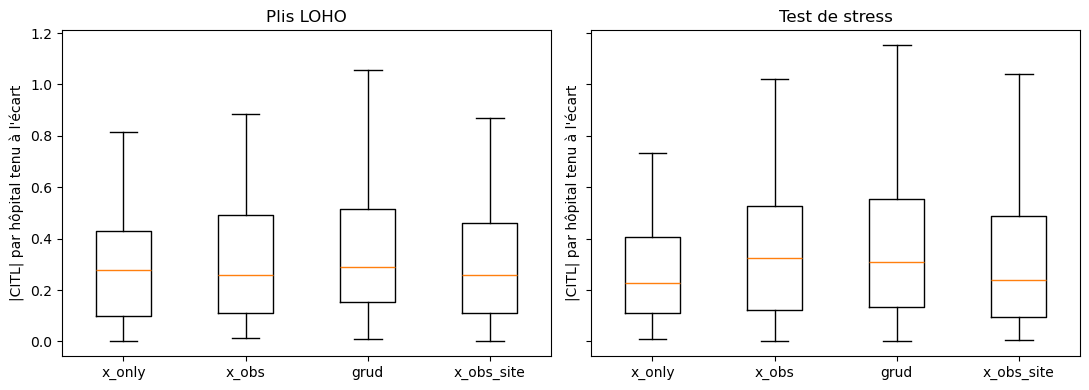

In [8]:
# ============================================================
# ÉTAPE 8 — RÉSULTATS DU TEST DE STRESS
# ============================================================
import matplotlib.pyplot as plt
S = runs_m[runs_m["protocol"] == "stress"]
agg = S.groupby(["split", "role", "model"])[["auroc", "macro_auroc", "cal_citl"]].agg(["mean", "std"])
tab_stress = pd.DataFrame({k: agg[(k, "mean")].map("{:.4f}".format) + " ± " + agg[(k, "std")].map("{:.4f}".format)
                           for k in ["auroc", "macro_auroc", "cal_citl"]})
tab_stress.to_csv(RES_DIR / "stress_summary.csv")
display(tab_stress)

def drop(R, model, split):
    w = R[(R["split"] == split) & (R["model"] == model)].pivot_table(index="seed", columns="role", values="auroc")
    return (w["intra"] - w["transfer"]).mean()

did_rows = []
for split in STRESS:
    for m in ["obs_only", "x_obs", "obs_site_only", "x_obs_site"]:
        did_rows.append({"sens": split, "modèle": m, "chute modèle": drop(S, m, split),
                         "chute x_only": drop(S, "x_only", split),
                         "différence de différences": drop(S, m, split) - drop(S, "x_only", split)})
did = pd.DataFrame(did_rows)
did.to_csv(RES_DIR / "stress_did.csv", index=False)
print("Chute d'AUROC intra -> transfert, comparée à x_only (> 0 : le modèle perd plus que x_only) :")
display(did.round(4))

w_stress = hospital_means(hosp_m[hosp_m["protocol"] == "stress"], "transfer", "cal_citl")
citl_stress = pd.DataFrame([compare_abs_citl(w_stress, a, b) for a, b in
                            [("x_only", "x_obs"), ("x_only", "grud"), ("x_obs", "x_obs_site"),
                             ("x_only", "x_obs_site"), ("obs_only", "obs_site_only")]])
citl_stress.to_csv(RES_DIR / "stress_citl_par_hopital.csv", index=False)
print("|CITL| par hôpital de transfert :")
display(citl_stress.round(4))

tr_stress = preds[(preds["protocol"] == "stress") & (preds["role"] == "transfer")]
meta_stress = pd.DataFrame([meta_auroc_gain(tr_stress, a, b, MIN_EVENTS_HOSP, N_BOOT) for a, b in
                            [("x_only", "x_obs"), ("x_obs", "x_obs_site"), ("x_only", "x_obs_site"),
                             ("obs_only", "obs_site_only")]])
meta_stress.to_csv(RES_DIR / "stress_meta_auroc.csv", index=False)
print("Méta-analyse des différences d'AUROC par hôpital (transfert) :")
display(meta_stress.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, w) in zip(axes, [("Plis LOHO", w_loho), ("Test de stress", w_stress)]):
    cols = [c for c in ["x_only", "x_obs", "grud", "x_obs_site"] if c in w.columns]
    ax.boxplot([w[c].abs().dropna() for c in cols], showfliers=False)
    ax.set_xticks(range(1, len(cols) + 1)); ax.set_xticklabels(cols)
    ax.set_title(title); ax.set_ylabel("|CITL| par hôpital tenu à l'écart")
plt.tight_layout()
plt.savefig(FIG_DIR / "citl_par_hopital.png", dpi=200)
plt.show()

## Étape 9 — Décision (critères fixés **avant** de voir les résultats)

| Code | Question | Mesure | Seuil |
|---|---|---|---|
| **N1** | Le niveau 2 réduit-il la décalibration par hôpital ? (plis LOHO) | \|CITL\| par hôpital tenu à l'écart, `x_obs_site` vs `x_obs` | médiane des différences < 0 et Wilcoxon p < 0,05 |
| **N2** | Le niveau 2 garde-t-il la discrimination ? (plis LOHO) | méta-analyse des différences d'AUROC par hôpital, `x_obs_site` − `x_obs` | borne basse de l'IC 95 % > −0,002 |
| **S1** | Le signal d'observation dépend-il de la politique de mesure ? | différence de différences de `obs_only` (étape 8) | > 0 dans les deux sens |
| **S2** | Le masque brut décalibre-t-il sous changement de politique ? | \|CITL\| par hôpital, `x_obs` vs `x_only` | médiane > 0 et Wilcoxon p < 0,05 |
| **S3** | Le niveau 2 corrige-t-il sous changement de politique ? | \|CITL\| par hôpital `x_obs_site` vs `x_obs` (médiane < 0, p < 0,05) **et** méta-analyse AUROC `x_obs_site` − `x_obs` (borne basse > −0,002) | les deux |

* **GO niveau 3** : (N1 ou S3) et N2 → l'encodage relatif au site apporte un bénéfice mesurable sans perte de discrimination ; on construit le modèle de propension (niveau 3), puis l'AKI.
* **COMPROMIS** : (N1 ou S3) sans N2 → meilleure calibration mais discrimination dégradée ; à discuter.
* **PROBLÈME SANS SOLUTION** : (S1 ou S2) sans (N1 ou S3) → le problème existe mais le centrage ne le corrige pas ; repenser l'encodage.
* **PLAN B** : aucun critère → l'article empirique devient l'axe principal.

In [9]:
# ============================================================
# ÉTAPE 9 — DÉCISION (CRITÈRES PRÉ-SPÉCIFIÉS)
# ============================================================
def row(df, comp):
    return df.set_index("comparaison").loc[comp]

c_n1 = row(citl_loho, "x_obs_site vs x_obs")
m_n2 = row(meta_loho, "x_obs_site - x_obs")
d_s1 = did[did["modèle"] == "obs_only"].set_index("sens")["différence de différences"]
c_s2 = row(citl_stress, "x_obs vs x_only")
c_s3 = row(citl_stress, "x_obs_site vs x_obs")
m_s3 = row(meta_stress, "x_obs_site - x_obs")

N1 = bool(c_n1["mediane_diff"] < 0 and c_n1["p_wilcoxon"] < 0.05)
N2 = bool(m_n2["ci_low"] > -0.002)
S1 = bool((d_s1 > 0).all())
S2 = bool(c_s2["mediane_diff"] > 0 and c_s2["p_wilcoxon"] < 0.05)
S3 = bool(c_s3["mediane_diff"] < 0 and c_s3["p_wilcoxon"] < 0.05 and m_s3["ci_low"] > -0.002)

crit = pd.DataFrame([
    {"code": "N1", "critère": "|CITL| LOHO x_obs_site vs x_obs", "valeur": f"médiane {c_n1['mediane_diff']:+.4f}, p = {c_n1['p_wilcoxon']:.3g}", "rempli": N1},
    {"code": "N2", "critère": "AUROC LOHO x_obs_site - x_obs", "valeur": f"{m_n2['pooled']:+.4f} [{m_n2['ci_low']:+.4f} ; {m_n2['ci_high']:+.4f}]", "rempli": N2},
    {"code": "S1", "critère": "obs_only plus fragile que x_only (stress)", "valeur": ", ".join(f"{k} {v:+.4f}" for k, v in d_s1.items()), "rempli": S1},
    {"code": "S2", "critère": "|CITL| stress x_obs vs x_only", "valeur": f"médiane {c_s2['mediane_diff']:+.4f}, p = {c_s2['p_wilcoxon']:.3g}", "rempli": S2},
    {"code": "S3", "critère": "stress : x_obs_site corrige x_obs", "valeur": f"|CITL| médiane {c_s3['mediane_diff']:+.4f}, p = {c_s3['p_wilcoxon']:.3g} ; AUROC {m_s3['pooled']:+.4f} [{m_s3['ci_low']:+.4f} ; {m_s3['ci_high']:+.4f}]", "rempli": S3},
])
display(crit)

fix, problem = (N1 or S3), (S1 or S2)
if fix and N2:
    verdict = "GO niveau 3 : l'encodage relatif au site apporte un bénéfice mesurable sans perte de discrimination."
elif fix:
    verdict = "COMPROMIS : meilleure calibration par hôpital mais discrimination dégradée."
elif problem:
    verdict = "PROBLÈME SANS SOLUTION : le problème existe mais le centrage par site ne le corrige pas."
else:
    verdict = "PLAN B : ni problème ni bénéfice mesurable du niveau 2."
print("\nVERDICT :", verdict)

report = f"""# Rapport — niveau 2 et test de stress (mortalité)

Protocole `{protocol['hash']}` | seeds {SEEDS} | alpha = {ALPHA} | {CFG}

## Plis LOHO
```
{tab_loho.to_string()}
```
```
{citl_loho.round(4).to_string(index=False)}
```
```
{meta_loho.round(4).to_string(index=False)}
```

## Test de stress
```
{tab_stress.to_string()}
```
```
{did.round(4).to_string(index=False)}
```
```
{citl_stress.round(4).to_string(index=False)}
```
```
{meta_stress.round(4).to_string(index=False)}
```

## Critères
```
{crit.to_string(index=False)}
```

**Verdict : {verdict}**
"""
(RES_DIR / "rapport_03.md").write_text(report, encoding="utf-8")
crit.to_csv(RES_DIR / "criteres_03.csv", index=False)
print("Écrit :", (RES_DIR / "rapport_03.md").resolve())

,code,critère,valeur,rempli
0,N1,|CITL| LOHO x_obs_site vs x_obs,"médiane -0.0076, p = 0.369",False
1,N2,AUROC LOHO x_obs_site - x_obs,+0.0007 [-0.0009 ; +0.0024],True
2,S1,obs_only plus fragile que x_only (stress),"haut_vers_bas -0.0176, bas_vers_haut +0.0181",False
3,S2,|CITL| stress x_obs vs x_only,"médiane +0.0297, p = 0.0334",True
4,S3,stress : x_obs_site corrige x_obs,"|CITL| médiane -0.0188, p = 0.669 ; AUROC -0.0...",False



VERDICT : PROBLÈME SANS SOLUTION : le problème existe mais le centrage par site ne le corrige pas.
Écrit : C:\Users\Stryve\Desktop\StryveSolution\Imagerie-Phd\P.H.D\New Impl\FUALA-w_28-06-2026\OP-FL-V2\results\03_niveau2_stress\rapport_03.md


## Étape 10 — Contrôles

La cellule échoue si un contrôle ne passe pas.

In [10]:
# ============================================================
# ÉTAPE 10 — CONTRÔLES
# ============================================================
checks = []
def check(name, ok):
    checks.append({"contrôle": name, "ok": bool(ok)})

locked = set(protocol["locked_test_hospitals"])
n_expected = sum(len(p[4]) for p in PLANS) * len(SEEDS)
n_done = sum(pred_path(p[0], p[1], m, s).exists() for p in PLANS for m in p[4] for s in SEEDS)
check(f"Toutes les exécutions de ce notebook sont terminées ({n_done}/{n_expected})", n_done == n_expected)
check("Hyperparamètres identiques au notebook 02", json.loads((RES02 / "config.json").read_text(encoding="utf-8"))["cfg"] == CFG)
check("Aucun hôpital du test verrouillé dans les prédictions", locked.isdisjoint(set(preds["hospitalid"])))
check(f"Groupes de stress disjoints et couvrant les {len(dev)} hôpitaux de dév.",
      set(low).isdisjoint(high) and set(low) | set(high) == set(dev))
ok = True
for proto, split, tr, ho, models in PLANS:
    g = preds[(preds["protocol"] == proto) & (preds["split"] == split)]
    ok &= set(g.loc[g["role"] == "transfer", "hospitalid"]) <= set(ho)
    ok &= set(g.loc[g["role"] == "intra", "hospitalid"]) <= set(tr)
check("Rôles corrects : transfert = hôpitaux tenus à l'écart, intra = hôpitaux d'entraînement", ok)
cov = preds[preds["role"] == "transfer"].groupby(["protocol", "model", "seed"])["hospitalid"].nunique()
check("Chaque hôpital de dév. évalué en transfert une fois par protocole, modèle et seed", (cov == len(dev)).all())
check("Probabilités finies et dans [0, 1]", np.isfinite(preds["p"]).all() and preds["p"].between(0, 1).all())
runs = pd.read_csv(RES_DIR / "runs.csv").drop_duplicates(["protocol", "split", "model", "seed"], keep="last")
ok_best = True
for f in HIST_DIR.glob("*.csv"):
    h = pd.read_csv(f)
    r = runs[(runs["protocol"] == h["protocol"].iloc[0]) & (runs["split"] == h["split"].iloc[0])
             & (runs["model"] == h["model"].iloc[0]) & (runs["seed"] == h["seed"].iloc[0])]
    ok_best &= len(r) == 1 and int(h.loc[h["val_auroc"].idxmax(), "round"]) == int(r["best_round"].iloc[0])
check("Meilleur round = maximum de l'AUROC sur val (sélection sur val uniquement)", ok_best)

res = pd.DataFrame(checks)
display(res)
if not res["ok"].all():
    raise AssertionError("Au moins un contrôle a échoué : voir le tableau ci-dessus.")
print("Tous les contrôles passent.")

,contrôle,ok
0,Toutes les exécutions de ce notebook sont term...,True
1,Hyperparamètres identiques au notebook 02,True
2,Aucun hôpital du test verrouillé dans les préd...,True
3,Groupes de stress disjoints et couvrant les 60...,True
4,Rôles corrects : transfert = hôpitaux tenus à ...,True
5,Chaque hôpital de dév. évalué en transfert une...,True
6,"Probabilités finies et dans [0, 1]",True
7,Meilleur round = maximum de l'AUROC sur val (s...,True


Tous les contrôles passent.
